-Martina Yed- Análisis y Procesamiento de Señales

TS2: Modelizando un ADC

a) Generar el siguiente resultado producto de la experimentación. B = 4 bits, kn=1.

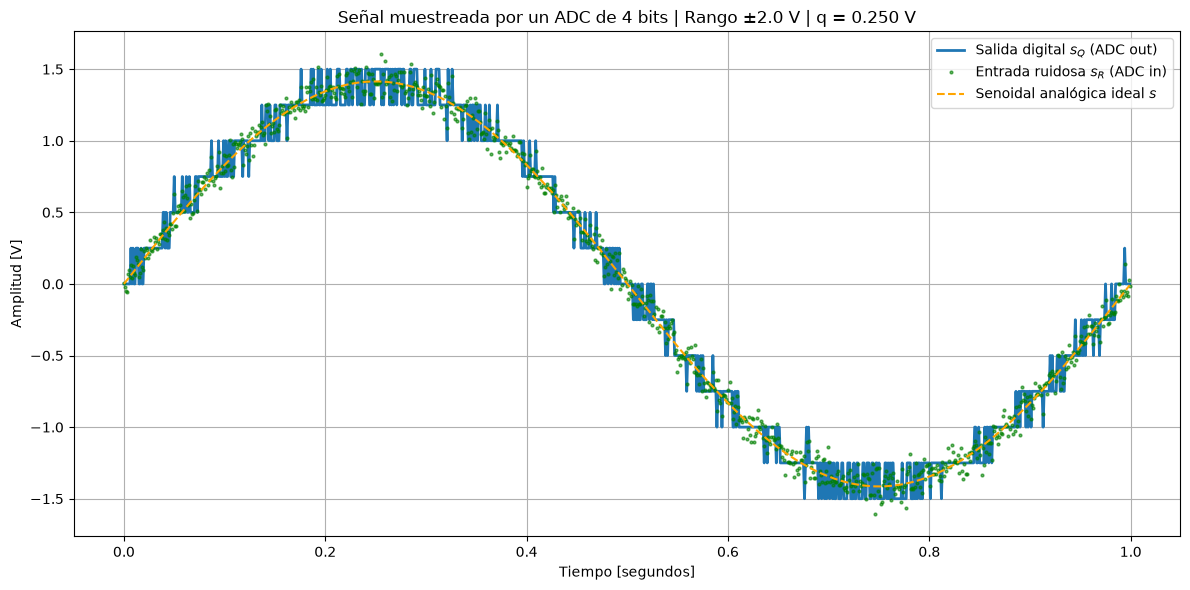

In [3]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000            # Frecuencia de muestreo [Hz]
N = 1000             # Cantidad de muestras (1 segundo)
Vref = 2.0             # Rango analógico ±2V
B = 4                # Resolución en bits
kn = 1.0             # Factor de potencia de ruido analógico vs digital
f0 = fs / N          # Frecuencia senoidal 1 Hz)

tt = np.arange(0, N) / fs
Vmax = np.sqrt(2)       
s = Vmax * np.sin(2 * np.pi * f0 * tt)

q = (2 * Vref) / (2**B)          # Escalón de cuantización (0.25 V)
Pq = (q**2) / 12               # Potencia teórica del ruido de cuantización
Pn = kn * Pq                   # Potencia del ruido analógico
n = np.random.normal(0, np.sqrt(Pn), N)

sR = s + n                     # Señal "sucia" que entra al ADC

# Bloque ADC
sQ = np.round(sR / q) * q
sQ = np.clip(sQ, -Vref, Vref - q)  # Saturación física


plt.figure(figsize=(12, 6))
plt.plot(tt, sQ, label=r'Salida digital $s_Q$ (ADC out)', linewidth=2)
plt.plot(tt, sR, 'g.', label=r'Entrada ruidosa $s_R$ (ADC in)', markersize=4, alpha=0.6)
plt.plot(tt, s, 'orange', linestyle='--', label=r'Senoidal analógica ideal $s$')


plt.title(rf'Señal muestreada por un ADC de {B} bits | Rango $\pm {Vref}$ V | q = {q:.3f} V')
plt.xlabel('Tiempo [segundos]')
plt.ylabel('Amplitud [V]')
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()

Al código que veníamos trabajando en clase le agregué las ecuaciones que forman la base matemática del simulador. Estas buscan representar cómo el ruido del ambiente se vincula directamente con las limitaciones físicas del conversor:
Escalón de cuantización ($q$): $q = \frac{2 V_F}{2^B}$. Representa la mínima diferencia de voltaje que el hardware puede detectar. Con 4 bits para un rango dinámico de 4 Volts, esta cuenta nos da los saltos de 0.25 V que vimos escalonando la senoidal en el gráfico temporal.
Potencia del ruido de cuantización ($P_q$): $P_q = \frac{q^2}{12}$. Representa cuánta energía tiene el error que comete el conversor al redondear la señal. Ese divisor de 12 viene de la estadística, asumiendo que el error de redondeo tiene una distribución uniforme entre un nivel de cuantización y el siguiente.
Potencia del ruido aditivo analógico ($P_n$): $P_n = k_n \cdot P_q$. En vez de inyectar un ruido analógico cualquiera con un SNR arbitrario, usamos el factor $k_n$ para vincular la interferencia externa directamente al error propio del ADC. Al elegir $k_n = 1$ para nuestro gráfico, forzamos matemáticamente un escenario donde el ruido de entrada afecta exactamente en la misma medida que la falta de resolución del equipo.
Generación de la interferencia ($\sigma_n$): Para crear esta "basura" analógica, le pasamos la desviación estándar $\sigma_n = \sqrt{P_n}$ a la función generadora de ruido gaussiano. Esto garantiza que la dispersión de los puntos verdes del gráfico contenga exactamente la potencia $P_n$.
Pisos de ruido en frecuencia: Agregamos $\bar{n} = 10 \log_{10}\left(\frac{2 P_n}{N}\right)$ y su equivalente digital $\bar{n}_Q$. Estas fórmulas toman la potencia total de los ruidos en el tiempo y calculan cómo esa energía se distribuye de manera uniforme a lo largo de los bines de frecuencia de la FFT.

En el gráfico temporal superponemos tres señales para entender qué está haciendo físicamente nuestro ADC de 4 bits:

-La línea punteada naranja: es nuestra señal ideal $s$, que nos sirve de referencia.
-Los puntos verdes: representan la señal $s_R$ que realmente le llega a la pata de entrada del conversor. Al estar "contaminada" con el ruido analógico Gaussiano, vemos que los puntos se dispersan alrededor de la senoidal ideal.
-La escalera azul: es finalmente la salida digital $s_Q$. Acá se ve perfecto el efecto de los 4 bits de resolución: el ADC tiene muy pocos "escalones" (16 en total) para representar la señal. 

Lo que podemos notar es que el ADC va tomando la señal verde (que ya venía con ruido) y la "fuerza" al escalón de tensión más cercano. Como en este caso configuramos $k_n = 1$, el ruido que ya traía la señal es del mismo orden de magnitud que el error que mete el ADC al redondear, por eso la salida azul a veces pega saltos un poco erráticos y no forma una escalera perfecta.

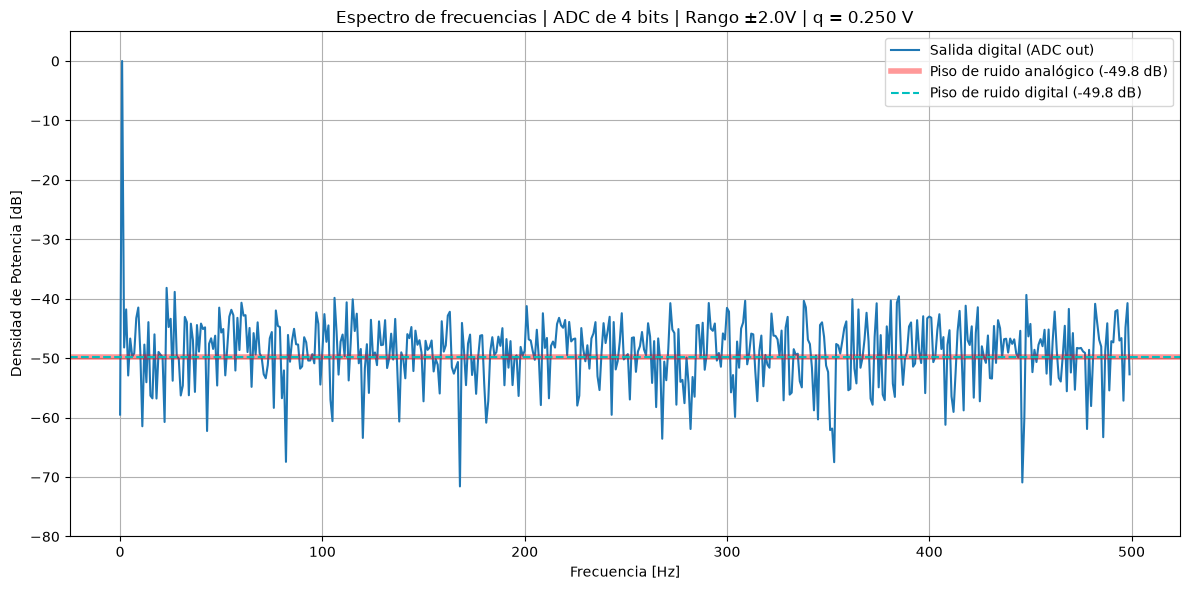

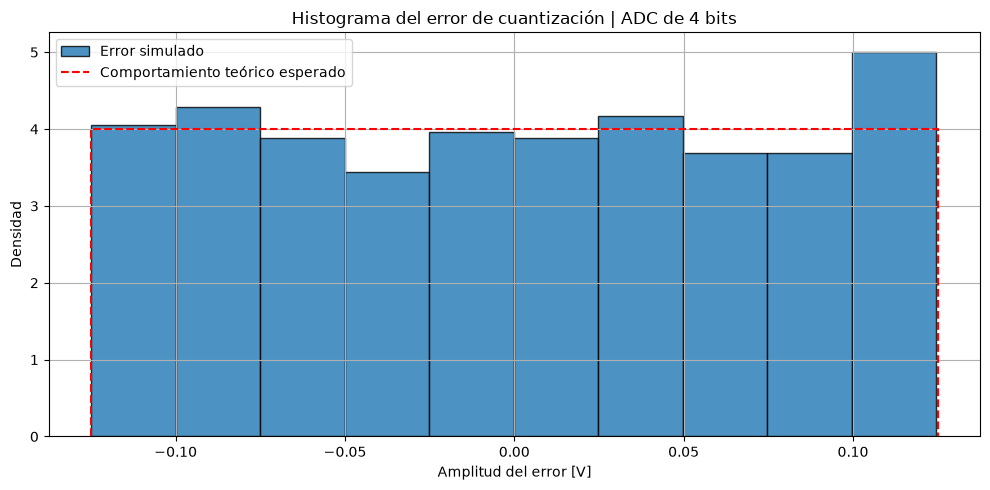

In [4]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000            
N = 1000             
Vref = 2.0             
B = 4                
kn = 1.0           
f0 = fs / N         
tt = np.arange(0, N) / fs
Vmax = np.sqrt(2)       
s = Vmax * np.sin(2 * np.pi * f0 * tt)
q = (2 * Vref) / (2**B)          
Pq = (q**2) / 12               
Pn = kn * Pq                  
n = np.random.normal(0, np.sqrt(Pn), N)
sR = s + n                     
sQ = np.round(sR / q) * q
sQ = np.clip(sQ, -Vref, Vref - q)  

k_freq = np.arange(N // 2)
freq = k_freq * (fs / N)

# FFT 
FFT_s = (1 / N) * np.fft.fft(s)[:N // 2]
FFT_sR = (1 / N) * np.fft.fft(sR)[:N // 2]
FFT_sQ = (1 / N) * np.fft.fft(sQ)[:N // 2]

# Densidad espectral 
mod_s_db = 10 * np.log10(2 * np.abs(FFT_s)**2 + 1e-12)
mod_sR_db = 10 * np.log10(2 * np.abs(FFT_sR)**2 + 1e-12)
mod_sQ_db = 10 * np.log10(2 * np.abs(FFT_sQ)**2 + 1e-12)

# Pisos medios teóricos 
piso_analog_db = 10 * np.log10((2 * Pn) / N)
piso_digital_db = 10 * np.log10((2 * Pq) / N)

nq = sQ - sR                  

plt.figure(figsize=(12, 6))
plt.plot(freq, mod_sQ_db, label='Salida digital (ADC out)', linewidth=1.5)
plt.axhline(y=piso_analog_db, color='r', linestyle='-', linewidth=4, alpha=0.4, label=f'Piso de ruido analógico ({piso_analog_db:.1f} dB)')
plt.axhline(y=piso_digital_db, color='c', linestyle='--', linewidth=1.5, label=f'Piso de ruido digital ({piso_digital_db:.1f} dB)')

plt.title(f'Espectro de frecuencias | ADC de {B} bits | Rango ±{Vref}V | q = {q:.3f} V')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Densidad de Potencia [dB]')
plt.ylim([-80, 5])
plt.grid(True)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(nq, bins=10, density=True, edgecolor='black', alpha=0.8, label='Error simulado')

plt.plot([-q/2, -q/2, q/2, q/2], [0, 1/q, 1/q, 0], 'r--', label='Comportamiento teórico esperado')

plt.title(f'Histograma del error de cuantización | ADC de {B} bits')
plt.xlabel('Amplitud del error [V]')
plt.ylabel('Densidad')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Para entender mejor cómo se comportan la señal y el ruido, pasamos al dominio de la frecuencia calculando la Transformada Rápida de Fourier (FFT) y graficando la densidad espectral de potencia en dB. 

En este gráfico podemos observar:
1. **El pico de la señal:** A la frecuencia de 1 Hz vemos el pico principal que corresponde a nuestra senoidal original. Como está en escala logarítmica (dB), resalta claramente por sobre el fondo.
2. **El ruido distribuido:** A diferencia de la señal que concentra toda su energía en una sola frecuencia, la energía del ruido (tanto el analógico como el de cuantización) se reparte a lo largo de todo el espectro. 
3. **Pisos medios teóricos:** Las líneas horizontales punteadas (roja y celeste) representan el valor teórico esperado para el ruido. Salen de tomar la potencia total del ruido ($P_n$ o $P_q$) y dividirla en partes iguales entre todos los bines de frecuencia ($N/2$). Como en este inciso a) pusimos $k_n = 1$, las potencias son iguales y por lo tanto el piso analógico y el digital están superpuestos en el mismo nivel de dB. Vemos que el espectro simulado (las líneas irregulares) oscila exactamente alrededor de este valor teórico medio.

Aislamos el ruido de cuantización haciendo la resta entre la señal que sale del ADC y la que entra ($n_q = s_Q - s_R$). Para analizar si el conversor se está comportando como dice la teoría, graficamos un histograma de estos errores.

**La teoría (línea roja punteada):** Asume que el error de redondeo del ADC tiene la misma probabilidad de caer en cualquier valor entre medio escalón hacia abajo ($-q/2$) y medio escalón hacia arriba ($q/2$). Esto forma una distribución de probabilidad uniforme, representada por la caja rectangular de altura $1/q$.
**La práctica (barras azules):** Al graficar la densidad real de los errores de nuestra simulación, vemos que las barras se acomodan bastante bien dentro del margen teórico de $\pm q/2$. Al tener solo 4 bits (16 niveles), la señal pasa pocas veces por cada escalón, por lo que el histograma no queda un rectángulo perfecto, pero aproxima de forma clara el comportamiento uniforme esperado matemáticamente.

b) Analizar para una de las siguientes configuraciones B = ̣{4, 8 y 16} bits, kn={1/10,1,10}. Discutir los resultados respecto a lo obtenido en a).

B=4 y Kn=0.1

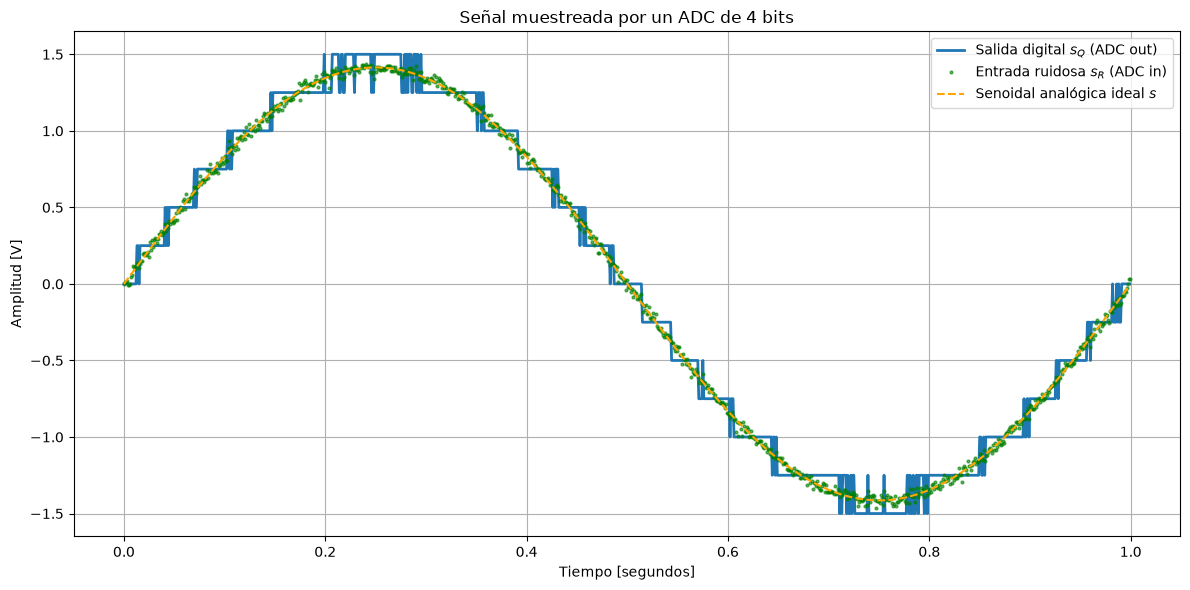

In [5]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000            # Frecuencia de muestreo [Hz]
N = 1000             # Cantidad de muestras (1 segundo)
Vref = 2.0             # Rango analógico ±2V
B = 4                # Resolución en bits
kn = 0.1             # Factor de potencia de ruido analógico vs digital
f0 = fs / N          # Frecuencia senoidal 1 Hz)

tt = np.arange(0, N) / fs
Vmax = np.sqrt(2)       
s = Vmax * np.sin(2 * np.pi * f0 * tt)

q = (2 * Vref) / (2**B)          # Escalón de cuantización (0.25 V)
Pq = (q**2) / 12               # Potencia teórica del ruido de cuantización
Pn = kn * Pq                   # Potencia del ruido analógico
n = np.random.normal(0, np.sqrt(Pn), N)

sR = s + n                     # Señal "sucia" que entra al ADC

# Bloque ADC
sQ = np.round(sR / q) * q
sQ = np.clip(sQ, -Vref, Vref - q)  # Saturación física


plt.figure(figsize=(12, 6))
plt.plot(tt, sQ, label=r'Salida digital $s_Q$ (ADC out)', linewidth=2)
plt.plot(tt, sR, 'g.', label=r'Entrada ruidosa $s_R$ (ADC in)', markersize=4, alpha=0.6)
plt.plot(tt, s, 'orange', linestyle='--', label=r'Senoidal analógica ideal $s$')


plt.title(rf'Señal muestreada por un ADC de {B} bits')
plt.xlabel('Tiempo [segundos]')
plt.ylabel('Amplitud [V]')
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()

Al configurar $k_n = 0.1$, definimos que la potencia del ruido analógico sea apenas la décima parte del ruido de cuantización ($P_n = 0.1 \cdot P_q$).Esto se refleja en los puntos verdes ($s_R$): están súper pegados a la línea punteada naranja (la senoidal ideal). La señal que le llega al conversor está prácticamente limpia de interferencias del entorno.
Al mantener el ADC en $B=4$ bits, el equipo sigue teniendo un escalón gigante de $q = 0.25$ V.La línea azul de salida ($s_Q$) dibuja una escalera con saltos muy bruscos. Al faltarle niveles de voltaje intermedios, destroza la forma original de la onda y no logra copiar la suavidad de los puntos verdes.Al haber tan poco ruido analógico en la entrada, la señal se queda "estancada" en los mismos escalones, dejando el error de redondeo del conversor totalmente expuesto.

El error de nuestro propio hardware domina absolutamente sobre la interferencia del entorno.La etapa analógica previa está entregando una señal de excelente calidad, pero la estamos destrozando al digitalizarla con una resolución tan pobre.

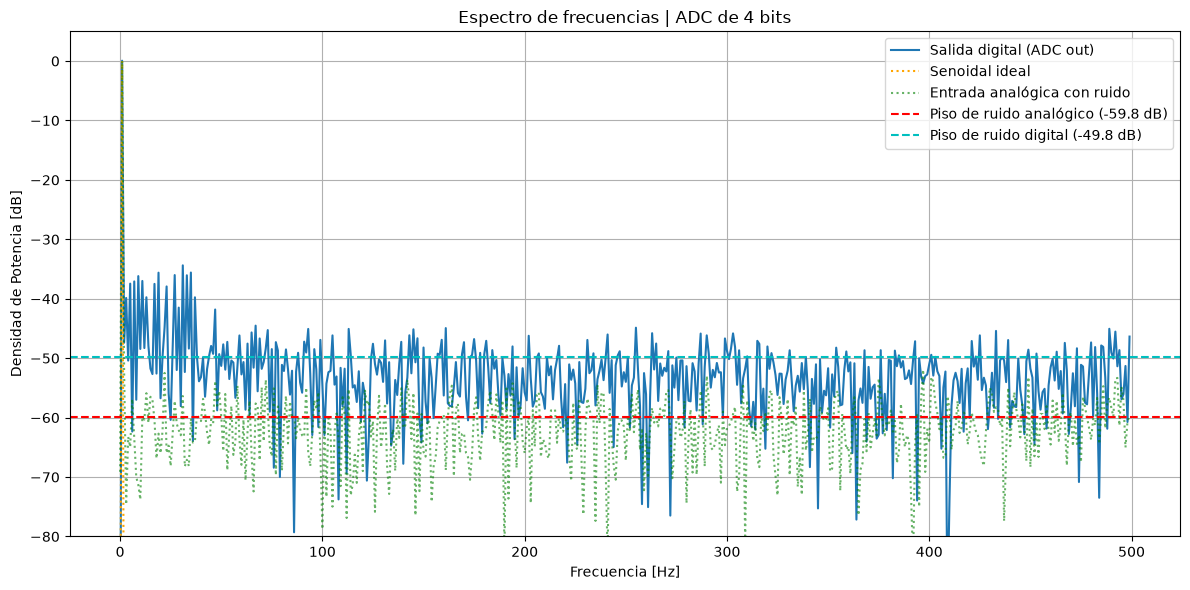

In [6]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000            
N = 1000             
Vref = 2.0             
B = 4                
kn = 0.1           
f0 = fs / N         
tt = np.arange(0, N) / fs
Vmax = np.sqrt(2)       
s = Vmax * np.sin(2 * np.pi * f0 * tt)
q = (2 * Vref) / (2**B)          
Pq = (q**2) / 12               
Pn = kn * Pq                  
n = np.random.normal(0, np.sqrt(Pn), N)
sR = s + n                     
sQ = np.round(sR / q) * q
sQ = np.clip(sQ, -Vref, Vref - q)  

k_freq = np.arange(N // 2)
freq = k_freq * (fs / N)
 
FFT_s = (1 / N) * np.fft.fft(s)[:N // 2]
FFT_sR = (1 / N) * np.fft.fft(sR)[:N // 2]
FFT_sQ = (1 / N) * np.fft.fft(sQ)[:N // 2]

mod_s_db = 10 * np.log10(2 * np.abs(FFT_s)**2 + 1e-12)
mod_sR_db = 10 * np.log10(2 * np.abs(FFT_sR)**2 + 1e-12)
mod_sQ_db = 10 * np.log10(2 * np.abs(FFT_sQ)**2 + 1e-12)

piso_analog_db = 10 * np.log10((2 * Pn) / N)
piso_digital_db = 10 * np.log10((2 * Pq) / N)

nq = sQ - sR                  

plt.figure(figsize=(12, 6))

plt.plot(freq, mod_sQ_db, label='Salida digital (ADC out)', linewidth=1.5)
plt.plot(freq, mod_s_db, 'orange', linestyle=':', label='Senoidal ideal')
plt.plot(freq, mod_sR_db, 'g:', label='Entrada analógica con ruido', alpha=0.6)

plt.axhline(y=piso_analog_db, color='r', linestyle='--', label=f'Piso de ruido analógico ({piso_analog_db:.1f} dB)')
plt.axhline(y=piso_digital_db, color='c', linestyle='--', label=f'Piso de ruido digital ({piso_digital_db:.1f} dB)')

plt.title(f'Espectro de frecuencias | ADC de {B} bits')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Densidad de Potencia [dB]')
plt.ylim([-80, 5])
plt.grid(True)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

En el dominio de la frecuencia vemos que el piso de ruido digital (marcado por los 4 bits) queda muy por encima del piso de ruido analógico.En este circuito no tiene ningún sentido invertir en mejores filtros analógicos; la única forma de mejorar la precisión de la medición es cambiar el ADC por uno de mayor resolución (por ejemplo, 8 o 16 bits) para achicar drásticamente ese escalón.

B=16 y K=10

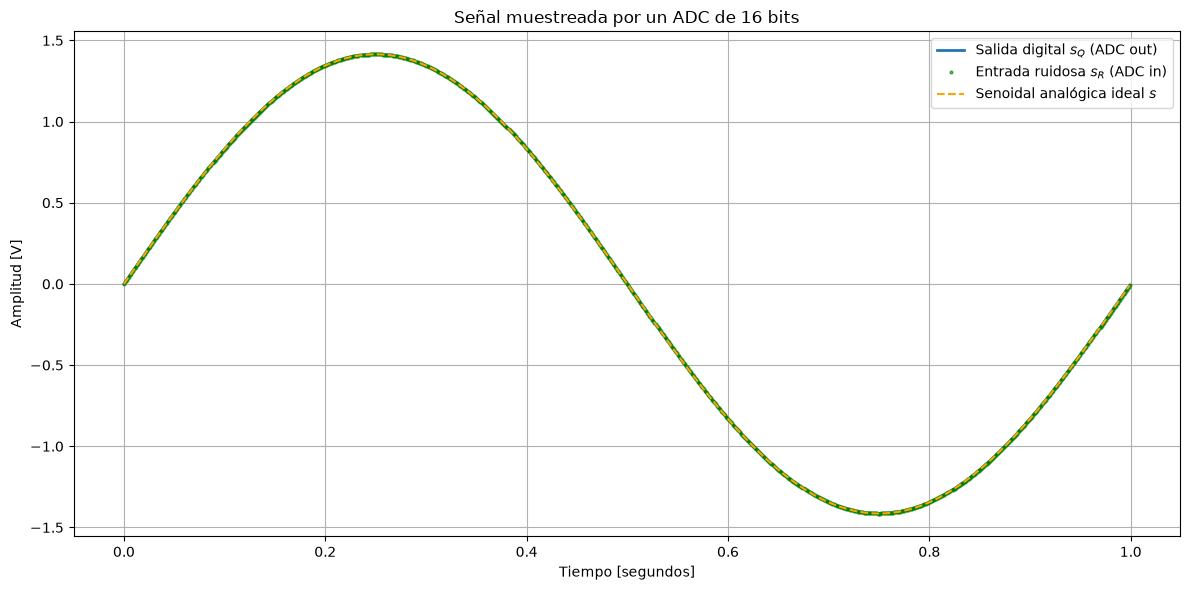

In [7]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000            # Frecuencia de muestreo [Hz]
N = 1000             # Cantidad de muestras (1 segundo)
Vref = 2.0             # Rango analógico ±2V
B = 16               # Resolución en bits
kn = 10            # Factor de potencia de ruido analógico vs digital
f0 = fs / N          # Frecuencia senoidal 1 Hz)

tt = np.arange(0, N) / fs
Vmax = np.sqrt(2)       
s = Vmax * np.sin(2 * np.pi * f0 * tt)

q = (2 * Vref) / (2**B)          # Escalón de cuantización (0.25 V)
Pq = (q**2) / 12               # Potencia teórica del ruido de cuantización
Pn = kn * Pq                   # Potencia del ruido analógico
n = np.random.normal(0, np.sqrt(Pn), N)

sR = s + n                     # Señal "sucia" que entra al ADC

# Bloque ADC
sQ = np.round(sR / q) * q
sQ = np.clip(sQ, -Vref, Vref - q)  # Saturación física


plt.figure(figsize=(12, 6))
plt.plot(tt, sQ, label=r'Salida digital $s_Q$ (ADC out)', linewidth=2)
plt.plot(tt, sR, 'g.', label=r'Entrada ruidosa $s_R$ (ADC in)', markersize=4, alpha=0.6)
plt.plot(tt, s, 'orange', linestyle='--', label=r'Senoidal analógica ideal $s$')


plt.title(rf'Señal muestreada por un ADC de {B} bits')
plt.xlabel('Tiempo [segundos]')
plt.ylabel('Amplitud [V]')
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()

Este es un escenario de alta resolución donde la interferencia externa domina por completo al hardware.
Al pasar a 16 bits, la cantidad de renglones disponibles es enorme ($2^{16} = 65536$ niveles). El escalón $q$ se vuelve tan microscópico que la señal de salida ($s_Q$) calca a la perfección los puntos verdes de entrada. El error del ADC ya no es visible a simple vista.

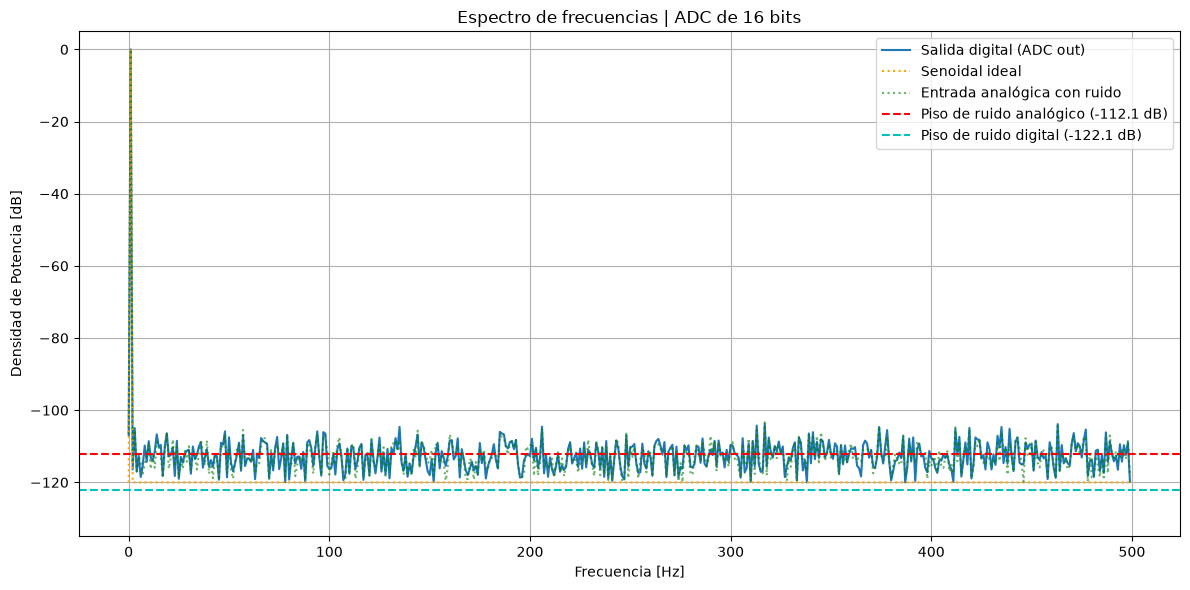

In [8]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000            
N = 1000             
Vref = 2.0             
B = 16               
kn = 10           
f0 = fs / N         
tt = np.arange(0, N) / fs
Vmax = np.sqrt(2)       
s = Vmax * np.sin(2 * np.pi * f0 * tt)
q = (2 * Vref) / (2**B)          
Pq = (q**2) / 12               
Pn = kn * Pq                  
n = np.random.normal(0, np.sqrt(Pn), N)
sR = s + n                     
sQ = np.round(sR / q) * q
sQ = np.clip(sQ, -Vref, Vref - q)  

k_freq = np.arange(N // 2)
freq = k_freq * (fs / N)

FFT_s = (1 / N) * np.fft.fft(s)[:N // 2]
FFT_sR = (1 / N) * np.fft.fft(sR)[:N // 2]
FFT_sQ = (1 / N) * np.fft.fft(sQ)[:N // 2]

mod_s_db = 10 * np.log10(2 * np.abs(FFT_s)**2 + 1e-12)
mod_sR_db = 10 * np.log10(2 * np.abs(FFT_sR)**2 + 1e-12)
mod_sQ_db = 10 * np.log10(2 * np.abs(FFT_sQ)**2 + 1e-12)

piso_analog_db = 10 * np.log10((2 * Pn) / N)
piso_digital_db = 10 * np.log10((2 * Pq) / N)

nq = sQ - sR                  

plt.figure(figsize=(12, 6))

plt.plot(freq, mod_sQ_db, label='Salida digital (ADC out)', linewidth=1.5)
plt.plot(freq, mod_s_db, 'orange', linestyle=':', label='Senoidal ideal')
plt.plot(freq, mod_sR_db, 'g:', label='Entrada analógica con ruido', alpha=0.6)

plt.axhline(y=piso_analog_db, color='r', linestyle='--', label=f'Piso de ruido analógico ({piso_analog_db:.1f} dB)')
plt.axhline(y=piso_digital_db, color='c', linestyle='--', label=f'Piso de ruido digital ({piso_digital_db:.1f} dB)')

plt.title(f'Espectro de frecuencias | ADC de {B} bits')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Densidad de Potencia [dB]')
plt.ylim([-135, 5])
plt.grid(True)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

La salida digital del ADC stán oscilando prolijamente abrazadas a la línea roja punteada, que marca el piso analógico en -112.1 dB. Como el ruido blanco distribuye su energía de forma pareja por todas las frecuencias (como vimos en el análisis espectral), se dibuja ese piso horizontal bien firme.
La línea celeste punteada (el ruido de cuantización de los 16 bits) quedó en -122.1 dB, exactamente 10 dB más abajo que el ruido analógico.
Un conversor de 16 bits es una máquina hiperprecisa (su ruido digital es microscópico), pero como le pusimos $k_n = 10$, la interferencia analógica del entorno es tan pesada que tapa por completo el error del ADC.

**Conclusión de la diferencia entre 4 bits y 8 bits**
La diferencia visual entre la señal de 4 bits y la de 8 bits se explica con el tamaño del escalón de cuantización ($q$). El rango dinámico de nuestra placa es fijo (4 Volts de extremo a extremo, ya que $V_F = \pm 2V$). Al configurar el ADC en 4 bits, el hardware divide ese espacio en apenas 16 niveles, obligando a la señal a dar saltos gigantes de 0.25 V ($q = \frac{4 \text{ V}}{16} = 0.25 \text{ V}$.). 

Al simular el ADC con 8 bits, pasamos a tener $2^8 = 256$ niveles disponibles en ese mismo espacio. Los escalones se vuelven de 0.015 V ($q = \frac{4 \text{ V}}{256} = 0.0156 \text{ V}$) que el error que comete el conversor al redondear se desploma. Por eso, al tener mayor cantidad de bits, la señal digital deja de verse como una escalera tosca y logra calcar casi a la perfección la suavidad de la curva analógica original.

BONUS

--Demostración del SNR vs. Cantidad de Bits ($B$)--

**Potencia de la señal ideal ($P_s$):** Para aprovechar todo el rango dinámico del ADC ($\pm V_F$), una senoidal debe tener una amplitud pico de $V_F$. Su potencia teórica es $P_s = \frac{V_F^2}{2}$.
**Potencia del ruido de cuantización ($P_q$):** Asumiendo una distribución uniforme del error, la varianza es $P_q = \frac{q^2}{12}$. Sabiendo que el tamaño del escalón es $q = \frac{2V_F}{2^B}$, al reemplazar y elevar al cuadrado obtenemos la potencia en función de los bits:$$P_q = \frac{4V_F^2}{12 \cdot 2^{2B}} = \frac{V_F^2}{3 \cdot 2^{2B}}$$
**Relación Señal a Ruido (Lineal):** Al dividir la potencia de la señal útil sobre la del ruido, el rango de voltaje se cancela y deja una proporción matemática pura:$$SNR = \frac{P_s}{P_q} = \frac{V_F^2 / 2}{V_F^2 / (3 \cdot 2^{2B})} = \frac{3}{2} \cdot 2^{2B}$$
**Conversión a Decibeles:** Aplicando el logaritmo base 10 para transformar esta ganancia:$$SNR_{dB} = 10 \log_{10}(1.5) + 10 \log_{10}(2^{2B}) \approx 1.76 + 6.02B$$

Al calcular la relación entre la señal ideal y el ruido ($P_s / P_q$), el rango dinámico ($V_F$) desaparece de la ecuación. Esto demuestra que la calidad (el SNR) del conversor depende exclusivamente de su cantidad de bits, y no de los voltajes que maneje.El término clave del resultado final es $6.02B$. Nos indica matemáticamente que por cada bit extra que le sumemos al hardware, ganamos unos 6 dB de relación señal a ruido.Sumar un solo bit significa duplicar la cantidad de "escalones" o niveles de cuantización disponibles. Al tener el doble de precisión, el conversor comete un error de redondeo muchísimo menor y la señal original queda mucho más "limpia" o despegada del piso de ruido.

Entocnes la conclusión es: a mayor cantidad de bits, mayor precisión.Al agregar un bit extra a un ADC, estamos duplicando la cantidad de escalones o niveles discretos disponibles para representar la señal. Como el rango total de voltaje sigue siendo el mismo (por ejemplo, los $\pm 2$ V que usamos mas arriba), cada uno de esos escalones se vuelve la mitad de alto.Al tener escalones más chicos, la diferencia entre el valor analógico real de la señal y el escalón más cercano al que el conversor la obliga a ir es mucho menor.Ese error más chico significa que el ruido de cuantización baja drásticamente, haciendo que la onda digital copie de manera mucho más fiel y suave a la curva analógica original.

![Demostración SNR Holton](Captura%20de%20pantalla%202026-09-02%20121248.png)

El código fue hecho con IA para poder bien la visualización del espectro y los pisos de ruido, facilitando la comparación de las señales.

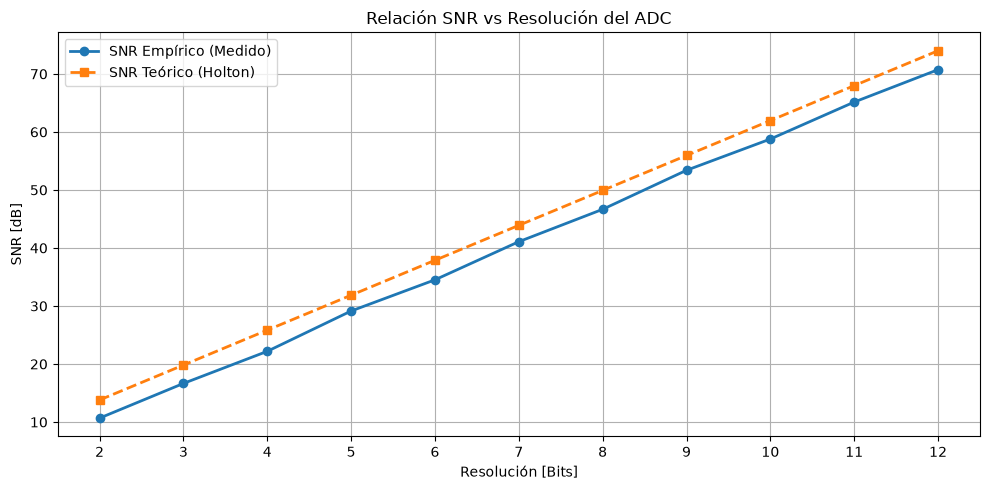

In [9]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000
N_muestras = 1000
Vref = 2.0
tt = np.arange(0, N_muestras) / fs
Vmax = np.sqrt(2)
f0 = 1.0
s_ideal = Vmax * np.sin(2 * np.pi * f0 * tt)

bits_array = np.arange(2, 13)
snr_empirico = []
snr_teorico = []

for B_test in bits_array:
    q_test = (2 * Vref) / (2**B_test)
    
    # Cuantización pura (sin ruido analógico)
    sQ_test = np.round(s_ideal / q_test) * q_test
    sQ_test = np.clip(sQ_test, -VF, VF - q_test)
    
    # Cálculo de potencias reales
    error_q = s_ideal - sQ_test
    pot_senal = np.var(s_ideal)
    pot_ruido = np.var(error_q)
    
    snr_medido = 10 * np.log10(pot_senal / pot_ruido)
    snr_empirico.append(snr_medido)
    
    # Cálculo teórico (aprox 6.02 dB por bit)
    snr_teorico.append(6.02 * B_test + 1.76)

plt.figure(figsize=(10, 5))
plt.plot(bits_array, snr_empirico, 'o-', linewidth=2, label='SNR Empírico (Medido)')
plt.plot(bits_array, snr_teorico, 's--', linewidth=2, label='SNR Teórico (Holton)')
plt.title('Relación SNR vs Resolución del ADC')
plt.xlabel('Resolución [Bits]')
plt.ylabel('SNR [dB]')
plt.xticks(bits_array)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


La curva empírica se solapa casi perfectamente con la recta teórica. 

--Simulación del efecto Aliasing--

La Transformada de Fourier de Tiempo Discreto (DTFT) es la herramienta matemática que permite tomar una secuencia de muestras en el dominio del tiempo y revelar exactamente de qué frecuencias está compuesta.
Si a un sistema Lineal e Invariante en el Tiempo (LTI) le ingresa una señal exponencial compleja, la salida será esa misma señal multiplicada por una constante. A este tipo de señales con esta propiedad referencial se las llama autofunciones del sistema. Esto significa que si introducimos una onda senoidal de una frecuencia específica, el sistema solo alterará su magnitud o su fase, pero la salida seguirá siendo una onda a esa misma frecuencia.  
Como es tan fácil predecir qué le hace un sistema a una exponencial compleja, la DTFT agarra cualquier señal de entrada arbitraria y la desarma en una suma de estas exponenciales. La ecuación te indica las "proporciones" exactas de las exponenciales en diferentes frecuencias que necesitás mezclar para sintetizar y reconstruir tu señal original. 
La DTFT produce una función $X(\omega)$ que es continua y se repite de forma periódica cada $2\pi$. Toda la información única y real de tu señal se concentra en un rango de valores principales, entre $-\pi$ y $\pi$. 
Como toda la información única de la señal se concentra exclusivamente en esa ventana principal de $-\pi$ a $\pi$, nuestra frecuencia máxima medible queda atrapada ahí adentro. En el mundo real del hardware, ese límite de $\pi$ equivale exactamente a la mitad de tu frecuencia de muestreo ($f_s/2$).
Si al conversor le entra una señal analógica que vibra más rápido que ese límite, la matemática la traduce a una frecuencia discreta que cae por fuera de la ventana de $\pm\pi$. Pero como en el dominio discreto todas las frecuencias son periódicas módulo $2\pi$, esa energía excedente no desaparece. En cambio, las frecuencias que quedan fuera del rango principal ingresan a la región sombreada de interés, plegándose hacia adentro de nuestra ventana útil. 

El aliasing es un error destructivo que no se puede arreglar por software. Una vez que el espectro se plegó al muestrear la señal, el procesador asume que ese pico fantasma es información legítima. La única forma de evitarlo es colocar un filtro analógico pasabajos duro antes de que la señal ingrese al pin del ADC, asegurando que cualquier componente por encima de $f_s/2$ sea atenuada antes de ser digitalizada.

Para simularlo vamos a mantener el reloj de $f_s = 1000$ Hz (límite de Nyquist en 500 Hz) y ponemos una senoidal de 800 Hz.

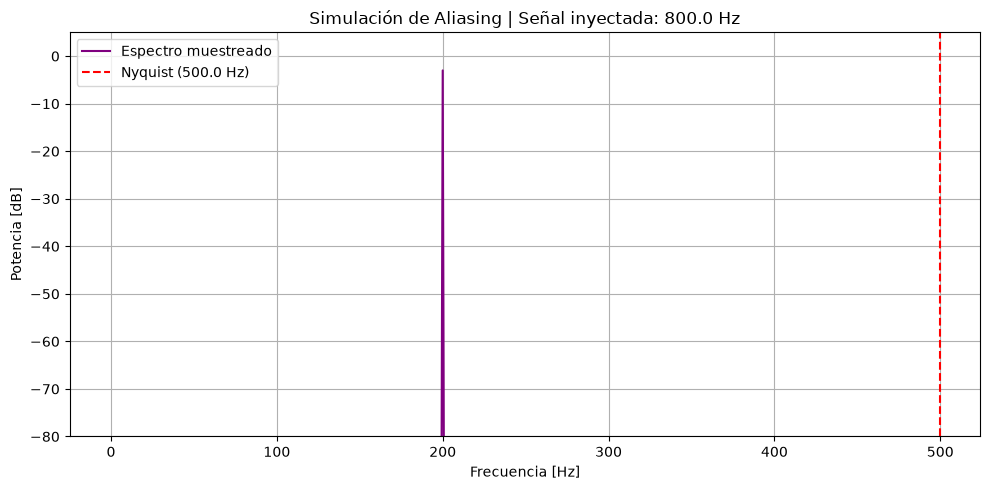

In [17]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000.0
N = 1000
tt = np.arange(N) / fs

# Señal real (800 Hz > fs/2)
f_real = 800.0
s_alias = np.sin(2 * np.pi * f_real * tt)

# Transformada de Fourier
FFT_alias = (1 / N) * np.fft.fft(s_alias)[:N // 2]
mod_alias_db = 10 * np.log10(2 * np.abs(FFT_alias)**2 + 1e-12)
freqs = np.arange(N // 2) * (fs / N)

plt.figure(figsize=(10, 5))
plt.plot(freqs, mod_alias_db, label='Espectro muestreado', color='purple', linewidth=1.5)
plt.axvline(x=fs/2, color='r', linestyle='--', label=f'Nyquist ({fs/2} Hz)')
plt.title(f'Simulación de Aliasing | Señal inyectada: {f_real} Hz')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Potencia [dB]')
plt.ylim([-80, 5])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

La señal original de 800 Hz se traduce a una frecuencia discreta de $1.6\pi$. Como esto escapa del rango principal $[-\pi, \pi)$, se le resta un período completo ($2\pi$), cayendo en $-0.4\pi$. Al devolver ese $-0.4\pi$ y tomar el valor absoluto (porque el espectro de amplitud de un coseno es simétrico), el pico de energía aparece exactamente anclado en $200$ Hz ($\vert{}1000 - 800\vert{}$). 
La línea punteada en 500 Hz marca la frecuencia de Nyquist. Como configuramos el reloj para tomar muastras a una velocidad de 1000 Hz, el sistema se vuelve matemáticamente incapaz de registrar cualquier evento que vibre más rápido que la mitad de esa frecuencia de muestreo (500 Hz).

Hacer este trabajo práctico me sirvió para bajar a tierra conceptos matemáticos. Al armar las simulaciones paso a paso, pude visualizar qué es lo que le pasa a una señal física cuando atraviesa un conversor.Lo principal que me llevo es que el hardware y el acondicionamiento previo funcionan como un sistema inseparable. Al variar el factor $k_n$, me quedó claro que no sirve de nada invertir en un ADC de 16 bits si la etapa analógica entrega una señal contaminada. Si el ruido del entorno es muy grande, el error microscópico de cuantización del conversor queda totalmente enmascarado y terminamos desperdiciando la capacidad del equipo. Buscar que el ruido digital y el analógico sean equivalentes ($k_n=1$) resulta en un diseño OPTIMO.  Por otro lado, comprobar con código que la curva empírica del SNR se superpone casi perfectamente con la fórmula teórica. Ver gráficamente que cada bit extra nos regala esos $\approx 6$ dB me ayudó a entender por qué achicar el tamaño del escalón de cuantización es la única forma de que la versión digital logre calcar la curva analógica.Finalmente, la simulación del aliasing. Ver cómo una onda de 800 Hz se disfraza de 200 Hz en el espectro solo por muestrear a 1000 Hz me hizo entender por qué el filtro pasabajos antialiasing es imp.